# IMC-HistoTools Tutorial 1: two-color virtual IHC of CRC


In [1]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile

# ---- Load the IMC_HistoTools package (repository root) ----
IMC_HistoTools_path = "/Users/gjhan/Documents/GitHub/Whole-Slide_IMC"
if IMC_HistoTools_path not in sys.path:
    sys.path.insert(0, IMC_HistoTools_path)

import IMC_HistoTools
from IMC_HistoTools.virtual_IHC import virtual_IHC, virtual_IHC_ROI
from IMC_HistoTools.annotation_region import virtual_IHC_annotation, Hscore_threshold
from IMC_HistoTools.pix_Hscore import pix_Hscore_plot_map, pix_Hscore_plot_bar

out_dir = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools")
out_dir.mkdir(parents=True, exist_ok=True)

print("IMC_HistoTools version:", IMC_HistoTools.__version__)
print("output dir:", out_dir)


IMC_HistoTools version: 0.2.0
output dir: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools


In [2]:
CRC = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/260927_virIHC/260923_yr-CRC_Ecad_2TSA")

Se_Ecadherin = tifffile.imread(CRC / "Normalize/ROI_001_Se_crop_normal.tiff").astype(np.float32)
DNA_CRC1      = tifffile.imread(CRC / "Normalize/ROI_001_191Ir-DNA191_Ir191_crop_normal.tiff").astype(np.float32)
DNA_CRC2      = tifffile.imread(CRC / "Normalize/ROI_001_193Ir-DNA193_Ir193_crop_normal.tiff").astype(np.float32)
mask         = tifffile.imread(CRC / "Mask/CRC_TM_mask_crop.tiff")
tissue       = mask > 0

geojson_path = Path("/Users/gjhan/Documents/Papers_submit/Selenium/Data/261003_Qpath/CRC_TM_raw_261003.geojson")

print("Se_Ecadherin :", Se_Ecadherin.shape)
print("tissue px    :", int(tissue.sum()), f"({100*tissue.mean():.1f}%)")
print("geojson      :", geojson_path.exists())


Se_Ecadherin : (2531, 3420)
tissue px    : 4535468 (52.4%)
geojson      : True


Blue  image: None -> replaced with an all-zero array
Red   image: None -> replaced with an all-zero array
Brown image: E-cadherin (Se), shape: (2531, 3420), dtype: float32


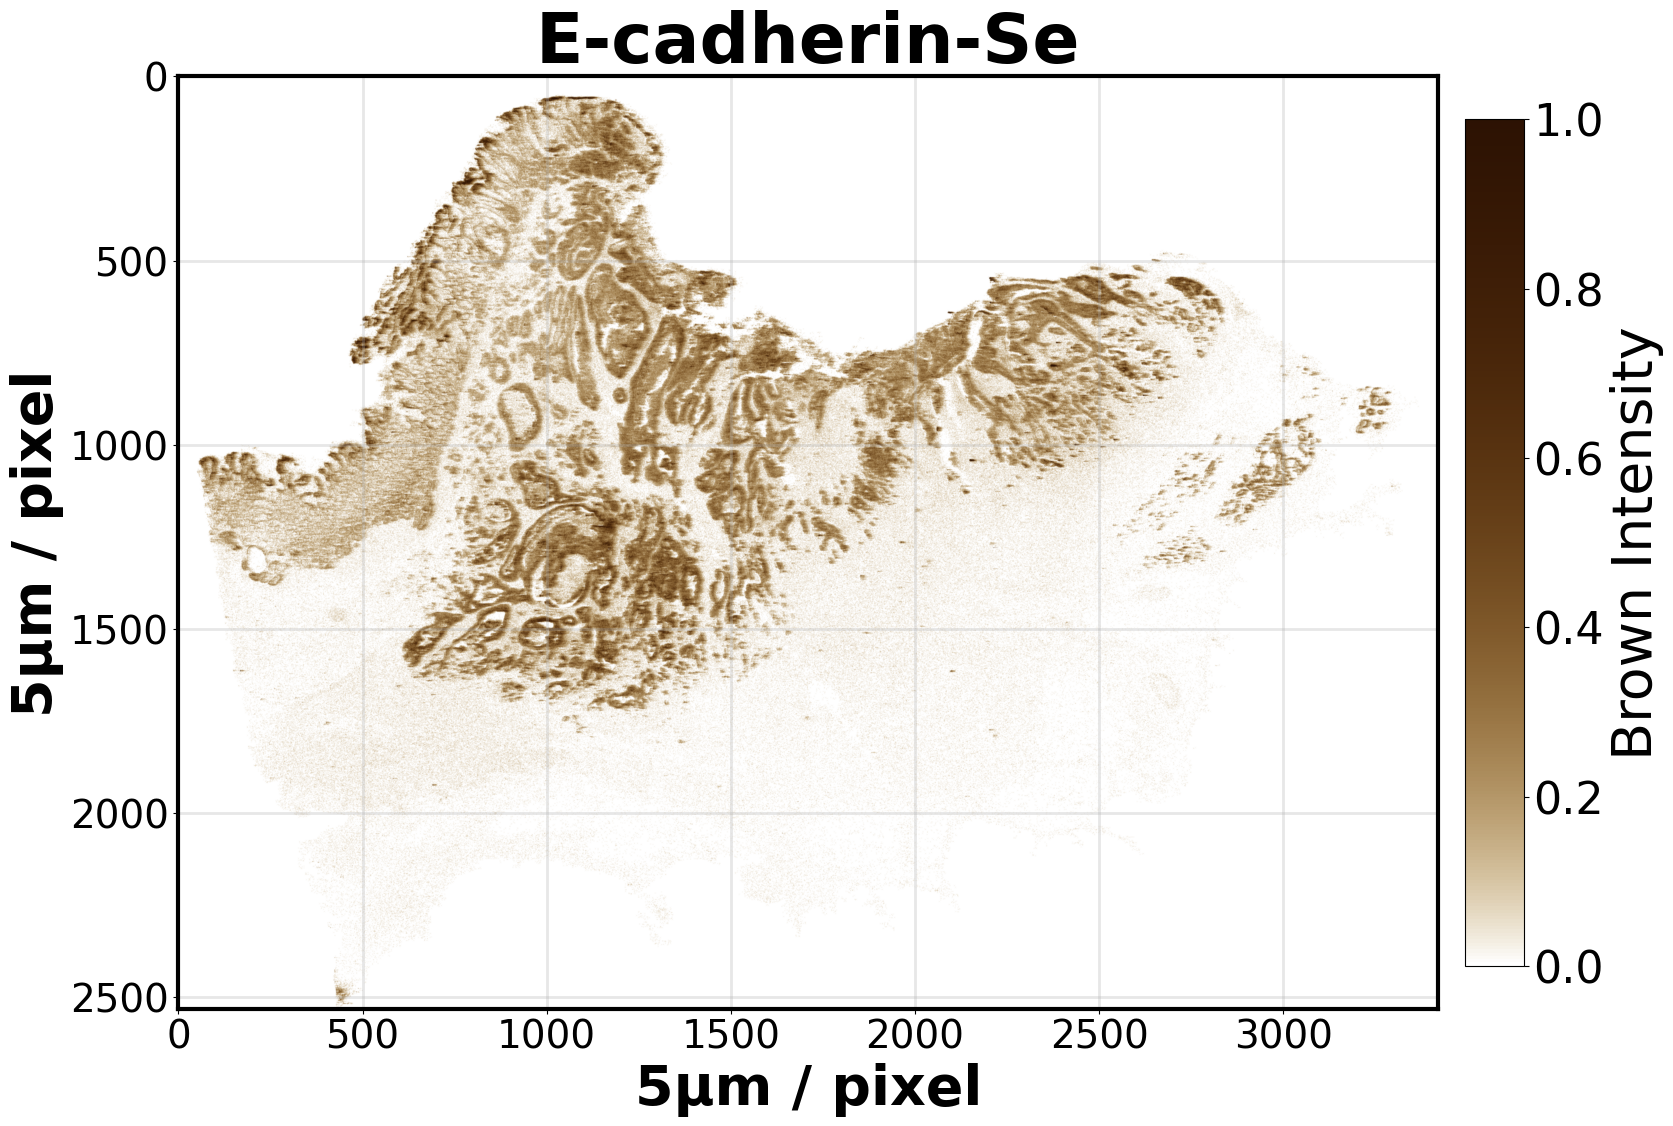

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC_raw.tiff


In [3]:
# virtual IHC from E-cadherin-Se

fig = virtual_IHC(Blue_image=None, 
                  Red_image=None, 
                  Brown_image=Se_Ecadherin,
                  blue_name="DNA", brown_name="E-cadherin (Se)",
                  brown_threshold=0.1,
                  title="E-cadherin-Se",
                  sigma=1, kernel_size=(3, 3),
                  k1=0.15, k3=0.5,
                  figsize=(24, 12),
                  grid=True,
                  grid_linewidth=2.0,
                  spine_linewidth=3.0,
                  tick_fontsize=28,
                  axis_label_fontsize=40,
                  bar_tick_fontsize=32,
                  axis_label_fontweight='bold',
                  tick_fontweight='normal',
                  bar_tick_fontweight='normal',
                  title_fontsize=50,
                  title_fontweight='bold',
                  tick_step=500, xlim=(0, Se_Ecadherin.shape[1]), ylim=(0, Se_Ecadherin.shape[0]),
                  brown_bar=True,
                  save_dir=str(out_dir / "CRC_virtual_IHC.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2531, 3420), dtype: float32
Red   image: None -> replaced with an all-zero array
Brown image: None -> replaced with an all-zero array


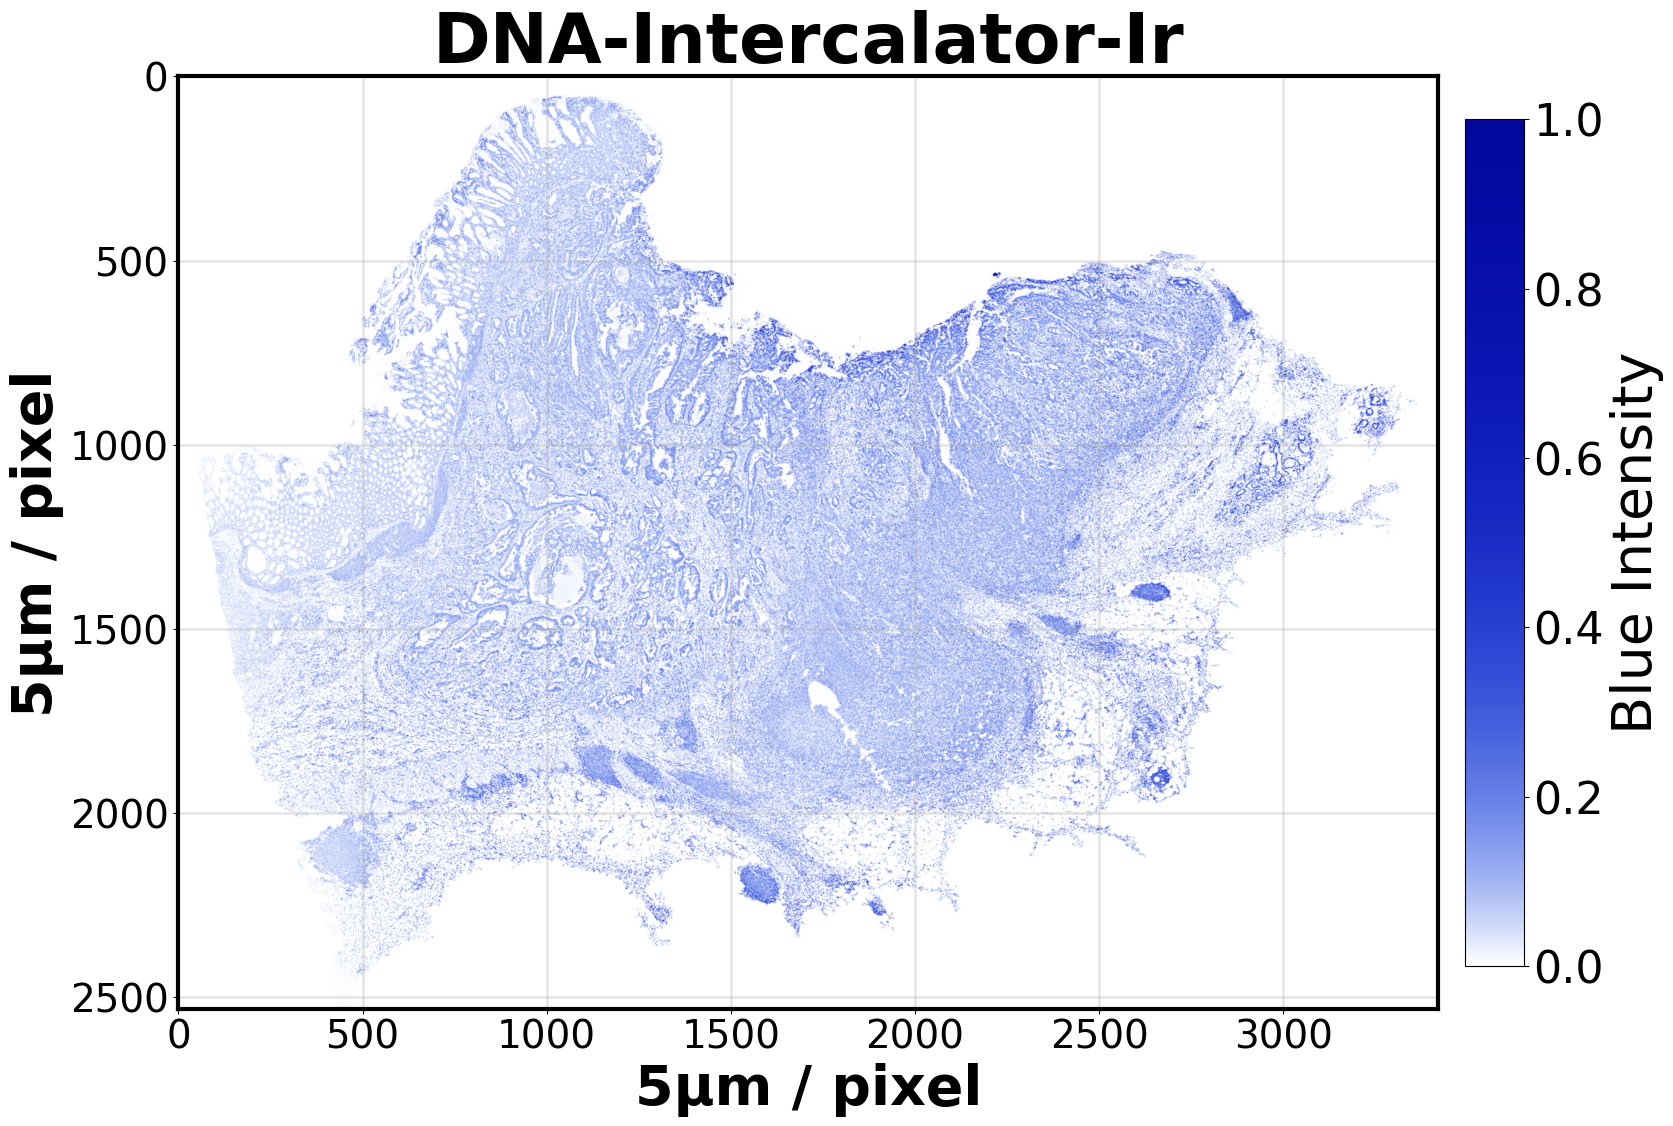

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC_raw.tiff


In [4]:
# virtual IHC from DNA-Intercalator-Ir

fig = virtual_IHC(Blue_image=DNA_CRC1 + DNA_CRC2, 
                  Red_image=None, 
                  Brown_image=None,
                  blue_name="DNA", brown_name="E-cadherin (Se)",
                  brown_threshold=0.1,
                  title="DNA-Intercalator-Ir",
                  sigma=1, kernel_size=(3, 3),
                  k1=0.25, k3=0.5,
                  figsize=(24, 12),
                  grid=True,
                  grid_linewidth=2.0,
                  spine_linewidth=3.0,
                  tick_fontsize=28,
                  axis_label_fontsize=40,
                  bar_tick_fontsize=32,
                  axis_label_fontweight='bold',
                  tick_fontweight='normal',
                  bar_tick_fontweight='normal',
                  title_fontsize=50,
                  title_fontweight='bold',
                  tick_step=500, xlim=(0, Se_Ecadherin.shape[1]), ylim=(0, Se_Ecadherin.shape[0]),
                  blue_bar=True,
                  save_dir=str(out_dir / "CRC_virtual_IHC.png"),
                  Save_raw=True,
                  save_dpi=300)

Blue  image: DNA,  shape: (2531, 3420), dtype: float32
Red   image: None -> replaced with an all-zero array
Brown image: E-cadherin (Se), shape: (2531, 3420), dtype: float32


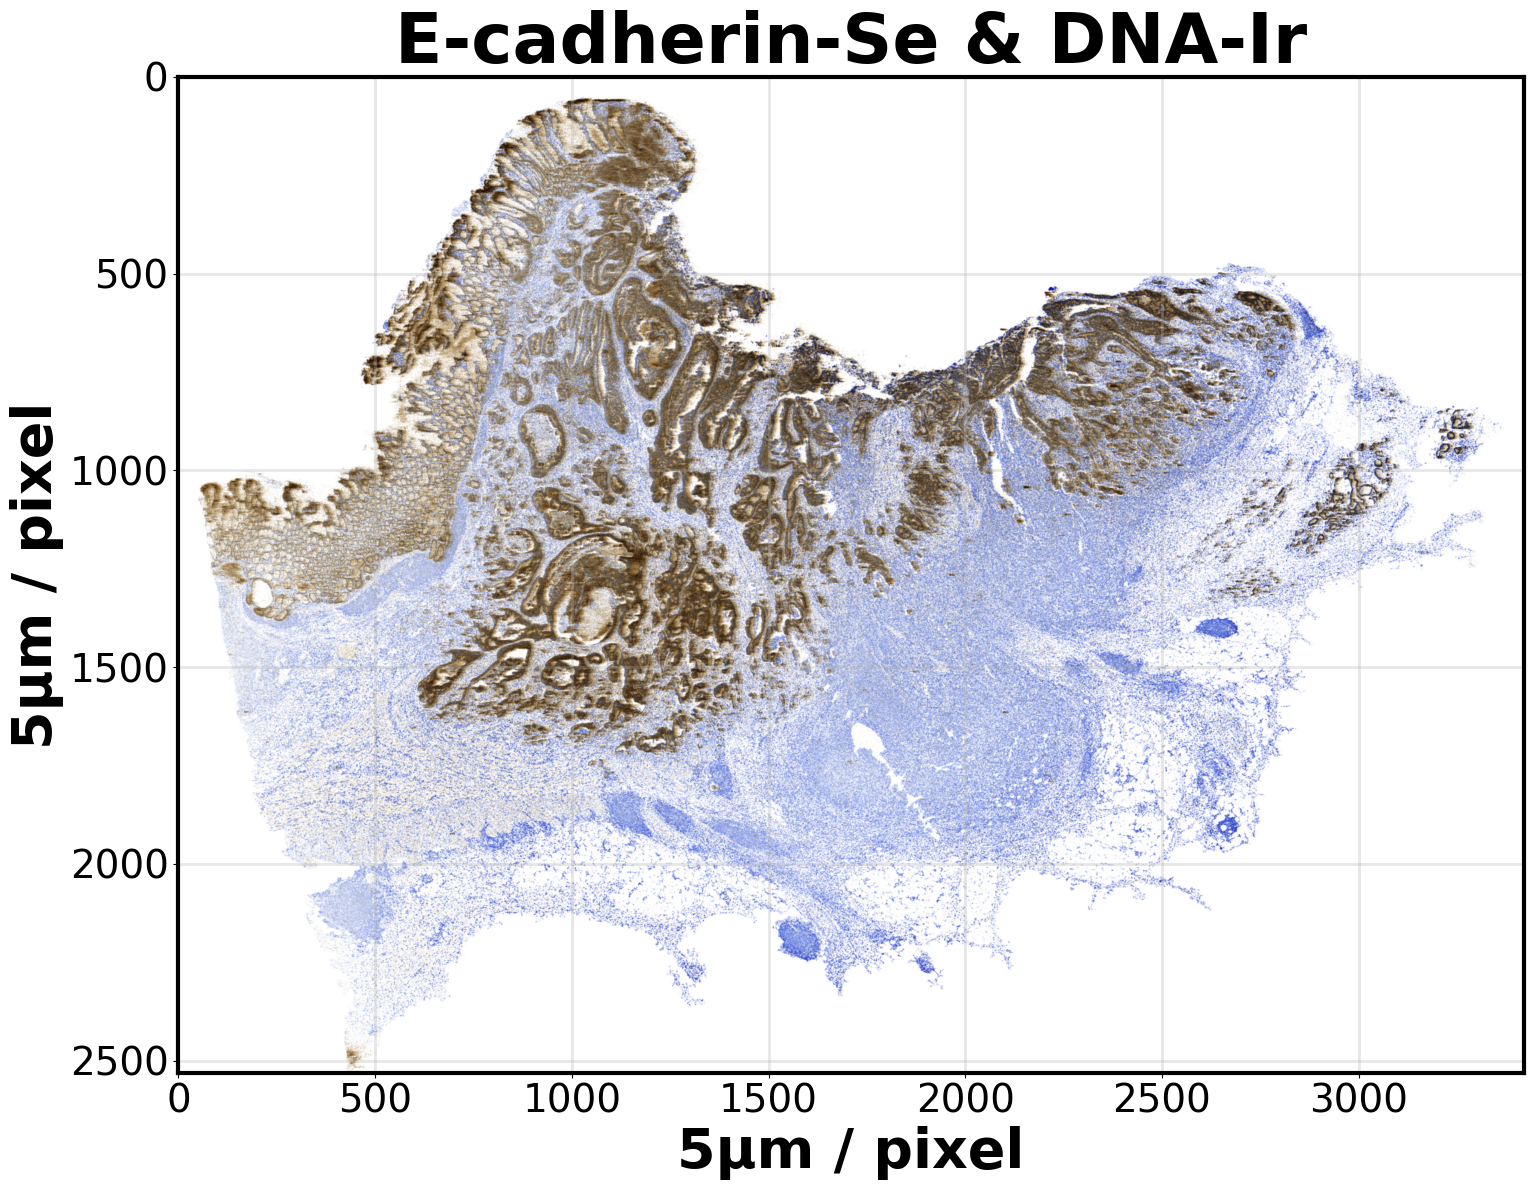

Figure saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC.png  (dpi=300)
Raw image saved to: /Users/gjhan/Documents/Papers_submit/Selenium/Data/261107_IMC_HistoTools/CRC_virtual_IHC_raw.tiff


In [5]:
# virtual IHC from E-cadherin-Se & DNA-Ir

fig = virtual_IHC(Blue_image=DNA_CRC1 + DNA_CRC2, 
                  Red_image=None, 
                  Brown_image=Se_Ecadherin,
                  blue_name="DNA", brown_name="E-cadherin (Se)",
                  brown_threshold=0.1,
                  title="E-cadherin-Se & DNA-Ir", 
                  sigma=1, kernel_size=(3, 3),
                  k1=0.25, k3=0.5,
                  figsize=(24, 12),
                  grid=True,
                  grid_linewidth=2.0,
                  spine_linewidth=3.0,
                  tick_fontsize=28,
                  axis_label_fontsize=40,
                  bar_tick_fontsize=32,
                  axis_label_fontweight='bold',
                  tick_fontweight='normal',
                  bar_tick_fontweight='normal',
                  title_fontsize=50,
                  title_fontweight='bold',
                  tick_step=500, xlim=(0, Se_Ecadherin.shape[1]), ylim=(0, Se_Ecadherin.shape[0]),
                  blue_bar=False,
                  save_dir=str(out_dir / "CRC_virtual_IHC.png"),
                  Save_raw=True,
                  save_dpi=300)